# Introduction
This script is about the computer vision analysis done through our camera.

Objectives:
- Camera calibration
- Definition of the actual position of the Thymio
- Definition of the final position
- Definition of the obstacles positions

In [1]:
!pip install opencv-python
!pip install numpy

## Camera calibration

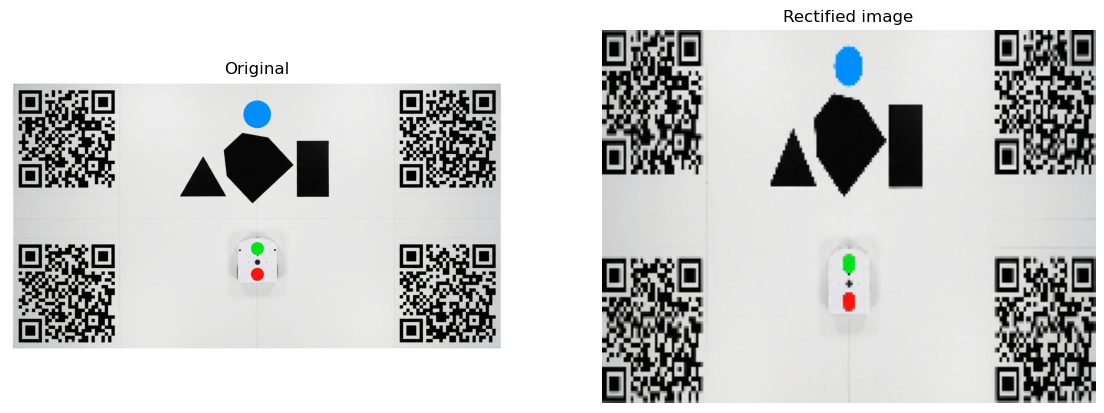

True

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
image = cv2.imread("ThymioSetup4.jfif")

if image is None:
    raise ValueError("Image not found")

# Detect QR codes
# QRCodeDetectorAruco is more robust: the standard QRCodeDetector
# sometimes finds only 3 of the 4 QR codes (e.g. ThymioSetup2/3)
def detect_qr_codes(image):
    for detector in (cv2.QRCodeDetectorAruco(), cv2.QRCodeDetector()):
        retval, points = detector.detectMulti(image)
        if retval and points is not None and len(points) == 4:
            return points
    return points

points = detect_qr_codes(image)

n_found = 0 if points is None else len(points)
if n_found != 4:
    raise ValueError(f"Exactly 4 QR codes are required, found {n_found}")

markers = points.reshape(4, 4, 2)

# Order each QR code's corners geometrically
def order_corners(p):
    s = p.sum(axis=1)
    d = np.diff(p, axis=1).flatten()

    return np.array([
        p[np.argmin(s)],  # top left
        p[np.argmin(d)],  # top right
        p[np.argmax(s)],  # bottom right
        p[np.argmax(d)]   # bottom left
    ], dtype=np.float32)

markers = np.array([
    order_corners(m) for m in markers
])

# Find QR code centers
centers = markers.mean(axis=1)

# Sort QR codes by vertical position
idx = np.argsort(centers[:, 1])

top = markers[idx[:2]]
bottom = markers[idx[2:]]

# Sort left to right
top = sorted(top, key=lambda p: p[:, 0].mean())
bottom = sorted(bottom, key=lambda p: p[:, 0].mean())

# Take ONLY the 4 external corners
src = np.array([
    top[0][0],       # top left QR: top left corner
    top[1][1],       # top right QR: top right corner
    bottom[1][2],    # bottom right QR: bottom right corner
    bottom[0][3]     # bottom left QR: bottom left corner
], dtype=np.float32)

# Desired rectangular output
width = 205
height = 155

dst = np.array([
    [0, 0],
    [width - 1, 0],
    [width - 1, height - 1],
    [0, height - 1]
], dtype=np.float32)

# Calculate homography
H = cv2.getPerspectiveTransform(src, dst)

# Rectify the entire image
rectified_image = cv2.warpPerspective(
    image,
    H,
    (width, height)
)

# Display (inline in Jupyter, no blocking OpenCV window)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(rectified_image, cv2.COLOR_BGR2RGB))
plt.title("Rectified image")
plt.axis("off")

plt.show()

cv2.imwrite("Rectified_Thymio.png", rectified_image)


## Actual position definition

Red point: 102 112
Green point: 102 96


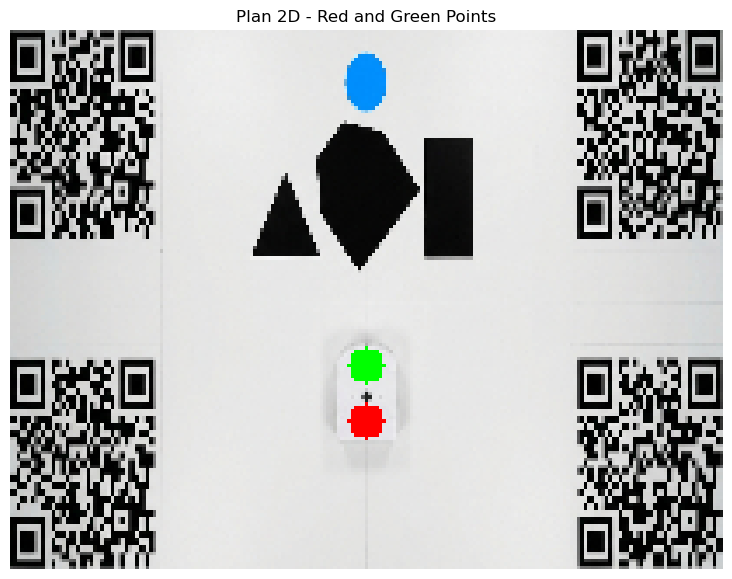

In [3]:

# ==========================================
# 1. CONVERT RECTIFIED IMAGE TO HSV
# ==========================================

hsv = cv2.cvtColor(rectified_image, cv2.COLOR_BGR2HSV)

# ==========================================
# 2. DEFINE COLOR RANGES
# ==========================================

# RED
lower_red1 = np.array([0, 100, 100])
upper_red1 = np.array([10, 255, 255])

lower_red2 = np.array([160, 100, 100])
upper_red2 = np.array([180, 255, 255])

# GREEN
lower_green = np.array([35, 80, 80])
upper_green = np.array([90, 255, 255])

# ==========================================
# 3. CREATE MASKS
# ==========================================

mask_red1 = cv2.inRange(hsv, lower_red1, upper_red1)
mask_red2 = cv2.inRange(hsv, lower_red2, upper_red2)

mask_red = cv2.bitwise_or(mask_red1, mask_red2)

mask_green = cv2.inRange(
    hsv,
    lower_green,
    upper_green
)

# ==========================================
# 4. FIND CONTOURS
# ==========================================

contours_red, _ = cv2.findContours(
    mask_red,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

contours_green, _ = cv2.findContours(
    mask_green,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# ==========================================
# 5. FETCH POSITIONS
# ==========================================

def find_position(contours):

    valid_contours = [
        c for c in contours
        if cv2.contourArea(c) > 5
    ]

    if not valid_contours:
        return None

    # Select largest detected object
    contour = max(valid_contours, key=cv2.contourArea)

    M = cv2.moments(contour)

    if M["m00"] == 0:
        return None

    x = int(M["m10"] / M["m00"])
    y = int(M["m01"] / M["m00"])

    return (x, y)


red_position = find_position(contours_red)
green_position = find_position(contours_green)

# ==========================================
# 6. DISPLAY POSITIONS
# ==========================================

result = rectified_image.copy()

if red_position is not None:

    x_red, y_red = red_position

    cv2.circle(
        result,
        red_position,
        5,
        (0, 0, 255),
        -1
    )

    print("Red point:", x_red, y_red)

else:
    print("Red point not detected")


if green_position is not None:

    x_green, y_green = green_position

    cv2.circle(
        result,
        green_position,
        5,
        (0, 255, 0),
        -1
    )

    print("Green point:", x_green, y_green)

else:
    print("Green point not detected")


# ==========================================
# 7. DISPLAY RESULT
# ==========================================

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Plan 2D - Red and Green Points")
plt.axis("off")
plt.show()


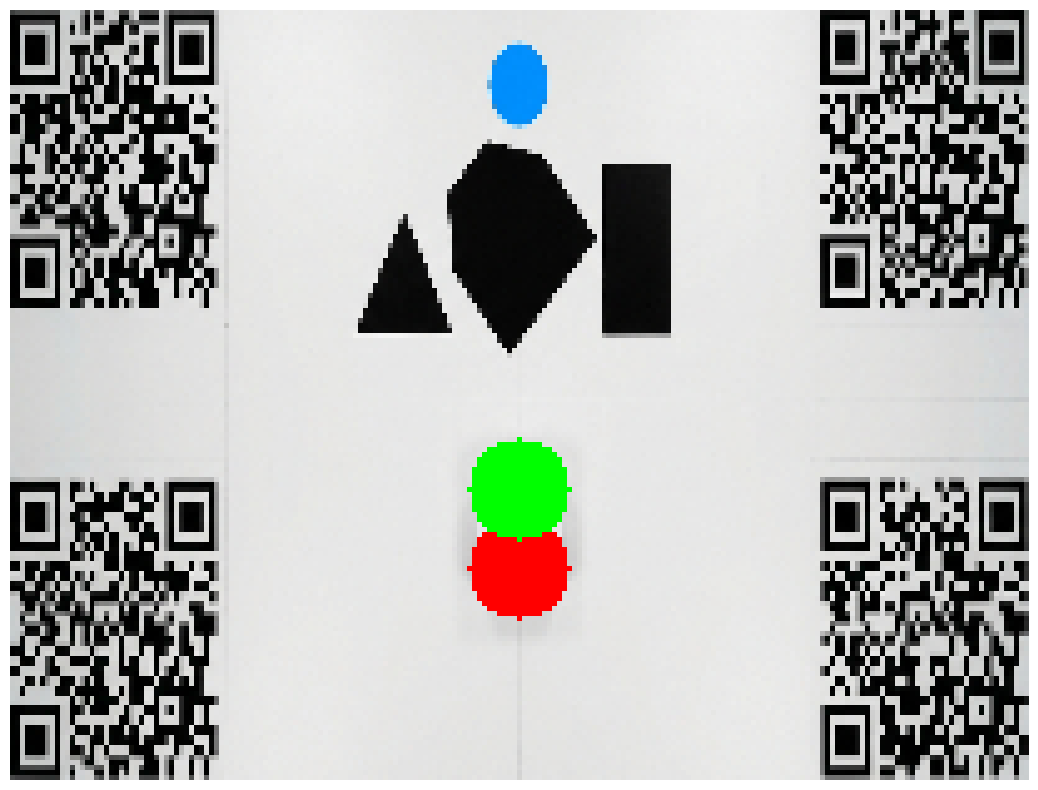

In [4]:
import matplotlib.pyplot as plt

# Copie de l'image rectifiée
image_display = rectified_image.copy()

# Dessiner les points détectés
if red_position is not None:
    cv2.circle(image_display, red_position, 10, (0, 0, 255), -1)

if green_position is not None:
    cv2.circle(image_display, green_position, 10, (0, 255, 0), -1)

# Afficher l'image en grand dans Jupyter
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(image_display, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.tight_layout()
plt.show()

## Final position definition

Blue point: 101 14


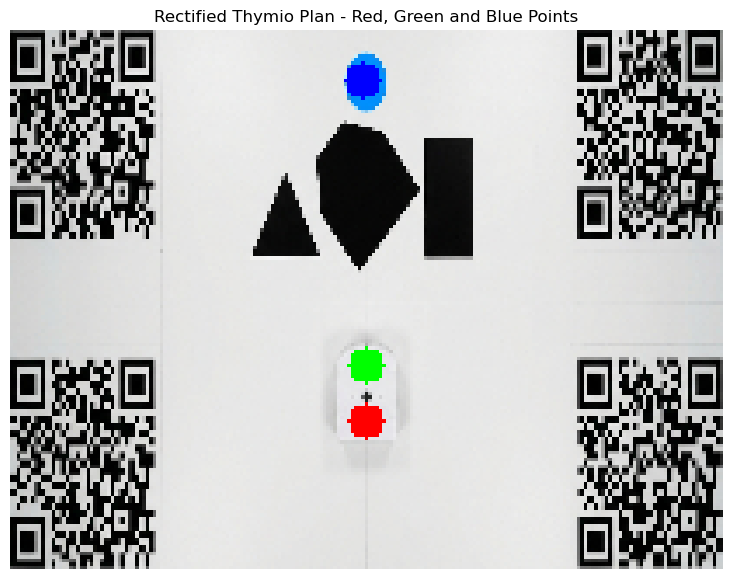

True

In [5]:

# ==========================================
# 8. FIND THE BLUE POINT
# ==========================================

# Define BLUE HSV range
lower_blue = np.array([100, 100, 100])
upper_blue = np.array([130, 255, 255])

# Create blue mask
mask_blue = cv2.inRange(
    hsv,
    lower_blue,
    upper_blue
)

# Find blue contours
contours_blue, _ = cv2.findContours(
    mask_blue,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# ==========================================
# 9. FETCH BLUE POSITION
# ==========================================

blue_position = find_position(contours_blue)

# ==========================================
# 10. DISPLAY BLUE POSITION
# ==========================================

if blue_position is not None:

    x_blue, y_blue = blue_position

    cv2.circle(
        result,
        blue_position,
        5,
        (255, 0, 0),  # Blue in BGR
        -1
    )

    print("Blue point:", x_blue, y_blue)

else:
    print("Blue point not detected")

# ==========================================
# DISPLAY FINAL IMAGE IN JUPYTER
# ==========================================

# Convert BGR to RGB for matplotlib
result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(result_rgb)
plt.title("Rectified Thymio Plan - Red, Green and Blue Points")
plt.axis("off")
plt.show()

# Save final image
cv2.imwrite("Final_Thymio_Points.png", result)


## Obstacle position definition

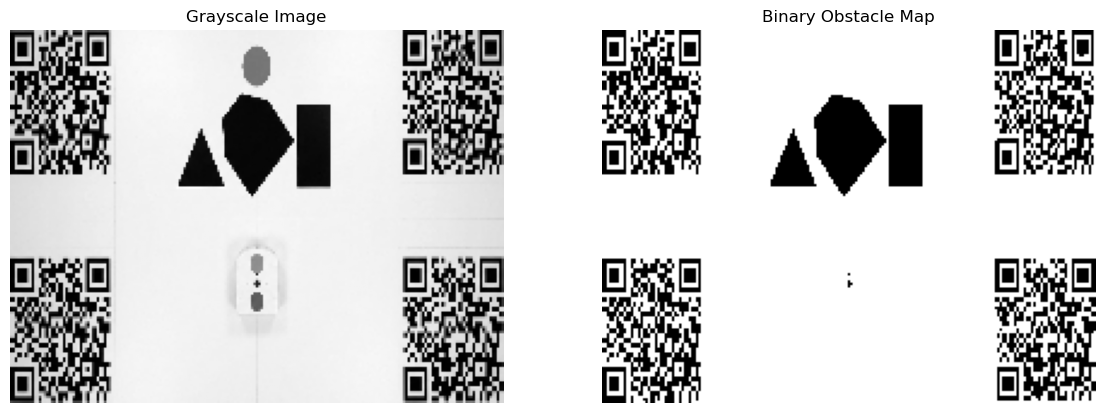

In [6]:

# ==========================================
# 1. DEFINE GREY THRESHOLD
# ==========================================

grey_threshold = 80

# ==========================================
# 2. CONVERT IMAGE TO GRAYSCALE
# ==========================================

grey_image = cv2.cvtColor(
    rectified_image,
    cv2.COLOR_BGR2GRAY
)

# ==========================================
# 3. CREATE BINARY OBSTACLE MATRIX
# ==========================================

# 0 = Obstacle (black)
# 1 = Free space (white)

obstacle_image = np.zeros(grey_image.shape, dtype=np.uint8)

for y in range(grey_image.shape[0]):
    for x in range(grey_image.shape[1]):

        if grey_image[y, x] <= grey_threshold:
            obstacle_image[y, x] = 0
        else:
            obstacle_image[y, x] = 255

# ==========================================
# 4. DISPLAY RESULTS IN JUPYTER
# ==========================================

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(grey_image, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(obstacle_image, cmap='gray', vmin=0, vmax=255)
plt.title("Binary Obstacle Map")
plt.axis("off")

plt.show()


## Final map: obstacles and points

Red point: x = 102, y = 112
Green point: x = 102, y = 96
Blue point: x = 101, y = 14
Thymio average position (red + green): x = 102.0, y = 104.0


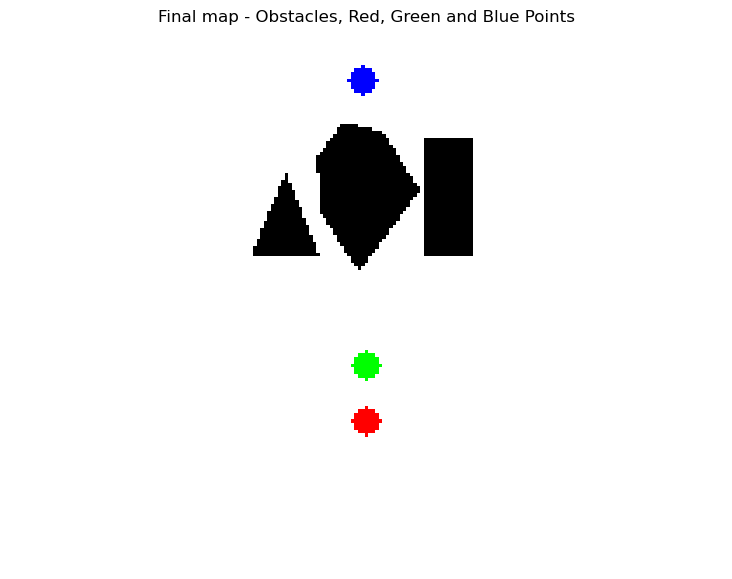

In [7]:

# ==========================================
# 1. WHITE BACKGROUND
# ==========================================

final_map = np.full((height, width, 3), 255, dtype=np.uint8)

# ==========================================
# 2. OBSTACLES IN BLACK
# ==========================================

# Reuse the binary obstacle map (0 = obstacle)
# The colored points are removed from the obstacles so they are not drawn in black
color_mask = cv2.bitwise_or(cv2.bitwise_or(mask_red, mask_green), mask_blue)
color_mask = cv2.dilate(color_mask, np.ones((3, 3), np.uint8), iterations=1)

obstacle_mask = (obstacle_image == 0) & (color_mask == 0)

# Remove the 4 QR codes: project their corners into the rectified image with H
qr_mask = np.zeros((height, width), dtype=np.uint8)
qr_corners_rectified = cv2.perspectiveTransform(markers.reshape(-1, 1, 2), H).reshape(4, 4, 2)

for qr in qr_corners_rectified:
    cv2.fillConvexPoly(qr_mask, np.round(qr).astype(np.int32), 255)

qr_mask = cv2.dilate(qr_mask, np.ones((5, 5), np.uint8), iterations=1)
obstacle_mask &= (qr_mask == 0)

# Remove the small noise blobs (keep only obstacles bigger than min_obstacle_area pixels)
min_obstacle_area = 20

n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    obstacle_mask.astype(np.uint8),
    connectivity=8
)

for label in range(1, n_labels):  # label 0 = background
    if stats[label, cv2.CC_STAT_AREA] < min_obstacle_area:
        obstacle_mask[labels == label] = False

final_map[obstacle_mask] = (0, 0, 0)

# ==========================================
# 3. RED, GREEN AND BLUE POINTS
# ==========================================

detected_points = {
    "Red":   (red_position,   (0, 0, 255)),   # BGR
    "Green": (green_position, (0, 255, 0)),
    "Blue":  (blue_position,  (255, 0, 0)),
}

for name, (position, color) in detected_points.items():
    if position is not None:
        cv2.circle(final_map, position, 4, color, -1)

# ==========================================
# 4. THYMIO AVERAGE POSITION (RED + GREEN)
# ==========================================

if red_position is not None and green_position is not None:
    thymio_position = (
        (red_position[0] + green_position[0]) / 2,
        (red_position[1] + green_position[1]) / 2
    )
else:
    thymio_position = None

# ==========================================
# 5. PRINT POSITIONS
# ==========================================

for name, (position, _) in detected_points.items():
    if position is not None:
        print(f"{name} point: x = {position[0]}, y = {position[1]}")
    else:
        print(f"{name} point not detected")

if thymio_position is not None:
    print(f"Thymio average position (red + green): x = {thymio_position[0]:.1f}, y = {thymio_position[1]:.1f}")
else:
    print("Thymio average position cannot be computed (red or green point missing)")

# ==========================================
# 6. DISPLAY FINAL MAP
# ==========================================

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(final_map, cv2.COLOR_BGR2RGB))
plt.title("Final map - Obstacles, Red, Green and Blue Points")
plt.axis("off")
plt.show()


## Global navigation: A* path
Shortest path from the Thymio (average of the red and green points) to the goal (blue point), on the obstacle map inflated by the robot radius.

Start (Thymio): x = 102, y = 104
Goal (blue):    x = 101, y = 14
Path found: 104 cells, length = 131.2 px


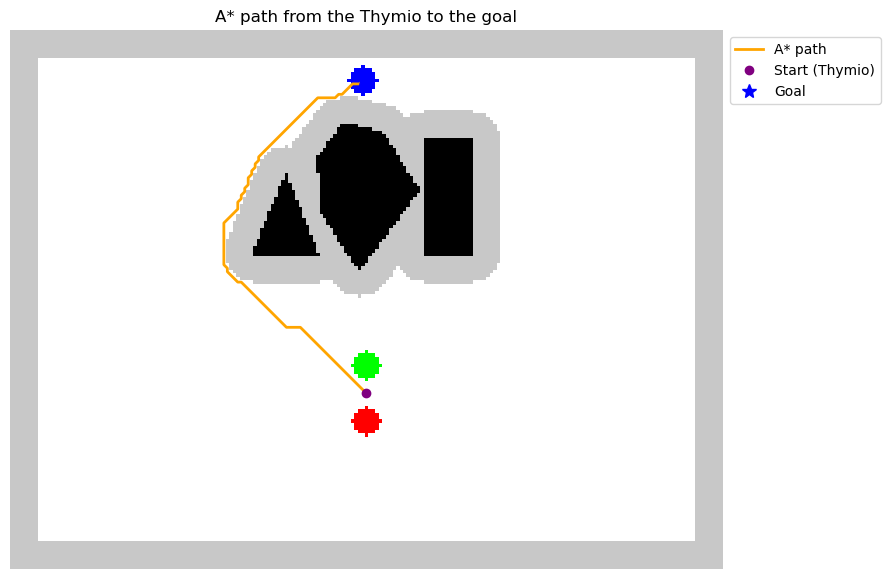

In [8]:

import heapq

# ==========================================
# 1. PARAMETERS
# ==========================================

# Half-size of the Thymio in pixels of the rectified map
# (the Thymio is ~11 cm wide, i.e. ~11-13 px here) + safety margin
robot_radius_px = 8

# ==========================================
# 2. START AND GOAL
# ==========================================

if thymio_position is None:
    raise ValueError("Start unknown: red or green point not detected")
if blue_position is None:
    raise ValueError("Goal unknown: blue point not detected")

# Grid cells are (row, col) = (y, x)
start = (int(round(thymio_position[1])), int(round(thymio_position[0])))
goal = (blue_position[1], blue_position[0])

# ==========================================
# 3. INFLATE OBSTACLES (CONFIGURATION SPACE)
# ==========================================

# The Thymio is not a point: grow every obstacle (and the map border)
# by the robot radius, then plan for the centre of the robot
kernel_size = 2 * robot_radius_px + 1
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))

inflated = cv2.dilate(obstacle_mask.astype(np.uint8), kernel)

inflated[:robot_radius_px, :] = 1
inflated[-robot_radius_px:, :] = 1
inflated[:, :robot_radius_px] = 1
inflated[:, -robot_radius_px:] = 1

occupancy_grid = inflated.astype(bool)   # True = forbidden cell

for name, cell in [("Start", start), ("Goal", goal)]:
    if occupancy_grid[cell]:
        print(f"Warning: {name} {cell[::-1]} is inside an inflated obstacle, it is forced to free")
        occupancy_grid[cell] = False

# ==========================================
# 4. A* ALGORITHM
# ==========================================

def heuristic(a, b):
    # Octile distance: exact cost on an 8-connected grid without obstacles
    dy, dx = abs(a[0] - b[0]), abs(a[1] - b[1])
    return (dx + dy) + (np.sqrt(2) - 2) * min(dx, dy)


def a_star(grid, start, goal):
    rows, cols = grid.shape

    # 8-connectivity: (d_row, d_col, cost)
    moves = [(-1, 0, 1), (1, 0, 1), (0, -1, 1), (0, 1, 1),
             (-1, -1, np.sqrt(2)), (-1, 1, np.sqrt(2)),
             (1, -1, np.sqrt(2)), (1, 1, np.sqrt(2))]

    open_set = [(heuristic(start, goal), 0.0, start)]   # (f, g, cell)
    came_from = {}
    g_score = {start: 0.0}
    closed = set()

    while open_set:
        _, g, current = heapq.heappop(open_set)

        if current == goal:
            # Rebuild the path from goal to start
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)
            return path[::-1], g

        if current in closed:
            continue
        closed.add(current)

        for d_row, d_col, cost in moves:
            neighbor = (current[0] + d_row, current[1] + d_col)

            if not (0 <= neighbor[0] < rows and 0 <= neighbor[1] < cols):
                continue
            if grid[neighbor] or neighbor in closed:
                continue

            # No corner cutting: a diagonal move needs both side cells free
            if d_row != 0 and d_col != 0:
                if grid[current[0] + d_row, current[1]] or grid[current[0], current[1] + d_col]:
                    continue

            new_g = g + cost
            if new_g < g_score.get(neighbor, np.inf):
                g_score[neighbor] = new_g
                came_from[neighbor] = current
                heapq.heappush(open_set, (new_g + heuristic(neighbor, goal), new_g, neighbor))

    return None, np.inf


path, path_length = a_star(occupancy_grid, start, goal)

# ==========================================
# 5. PRINT RESULT
# ==========================================

print(f"Start (Thymio): x = {start[1]}, y = {start[0]}")
print(f"Goal (blue):    x = {goal[1]}, y = {goal[0]}")

if path is None:
    print("No path found between the Thymio and the goal")
else:
    print(f"Path found: {len(path)} cells, length = {path_length:.1f} px")

# ==========================================
# 6. DISPLAY PATH ON THE FINAL MAP
# ==========================================

path_map = final_map.copy()

# Inflated zone (forbidden for the robot centre) in light grey
path_map[occupancy_grid & ~obstacle_mask] = (200, 200, 200)

# Redraw the points on top of the grey zone
for name, (position, color) in detected_points.items():
    if position is not None:
        cv2.circle(path_map, position, 4, color, -1)

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(path_map, cv2.COLOR_BGR2RGB))

if path is not None:
    path_xy = np.array(path)[:, ::-1]   # (row, col) -> (x, y)
    plt.plot(path_xy[:, 0], path_xy[:, 1], color="orange", linewidth=2, label="A* path")

plt.plot(start[1], start[0], "o", color="purple", markersize=6, label="Start (Thymio)")
plt.plot(goal[1], goal[0], "*", color="blue", markersize=10, label="Goal")

plt.title("A* path from the Thymio to the goal")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.axis("off")
plt.show()
